In [16]:
# Imports

import os
import shutil
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Configuration

SEED = 123
IMG_HEIGHT = 150
IMG_WIDTH = 150
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32
EPOCHS = 10
VALIDATION_SPLIT = 0.20

# Reproducibility

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Directories

BASE_DIR = Path("data")
ORIGINAL_TRAIN_DIR = BASE_DIR / "train"
TEST_DIR = BASE_DIR / "test"

TRAIN_DIR = BASE_DIR / "train_split"
VALIDATION_DIR = BASE_DIR / "validation"

MODEL_DIR = Path("models")
RESULTS_DIR = Path("results")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "cats_vs_dogs_best.keras"

# Display configuration

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Training directory:", ORIGINAL_TRAIN_DIR)
print("Test directory:", TEST_DIR)

TensorFlow version: 2.21.0
GPU devices: []
Image size: (150, 150)
Batch size: 32
Epochs: 10
Training directory: data\train
Test directory: data\test


In [17]:
# Check whether dataset directories exist

required_directories = [
    ORIGINAL_TRAIN_DIR,
    TEST_DIR
]

for directory in required_directories:
    if not directory.is_dir():
        raise FileNotFoundError(
            f"Directory not found: {directory.resolve()}"
        )

for directory in required_directories:
    for class_name in ["cats", "dogs"]:
        class_dir = directory / class_name

        if not class_dir.is_dir():
            raise FileNotFoundError(
                f"Expected class directory not found: {class_dir.resolve()}"
            )

print("Dataset directory structure is correct.")

FileNotFoundError: Directory not found: D:\Data Science and Analytics Journey\CATS VS DOGS\tensorflow-end-to-end-image-classifier\data\train

In [8]:
# Data paths

BASE_DIR = "data"

ORIGINAL_TRAIN_DIR = os.path.join(BASE_DIR, "train")
TEST_DIR = os.path.join(BASE_DIR, "test")

TRAIN_DIR = os.path.join(BASE_DIR, "train_split")
VALIDATION_DIR = os.path.join(BASE_DIR, "validation")

print("Original train directory:", ORIGINAL_TRAIN_DIR)
print("Test directory:", TEST_DIR)

Original train directory: data\train
Test directory: data\test


In [9]:
# Count images in each category

def count_images(directory):
    counts = {}

    for class_name in ["cats", "dogs"]:
        class_dir = os.path.join(directory, class_name)

        if os.path.exists(class_dir):
            counts[class_name] = len(
                [
                    file
                    for file in os.listdir(class_dir)
                    if file.lower().endswith(
                        (".jpg", ".jpeg", ".png")
                    )
                ]
            )
        else:
            counts[class_name] = 0

    return counts

In [10]:
# Check training data distribution

train_counts = count_images(ORIGINAL_TRAIN_DIR)

print("Training data:")
print(train_counts)

Training data:
{'cats': 0, 'dogs': 0}


In [11]:
# Check test data distribution

test_counts = count_images(TEST_DIR)

print("\nTest data:")
print(test_counts)


Test data:
{'cats': 0, 'dogs': 0}


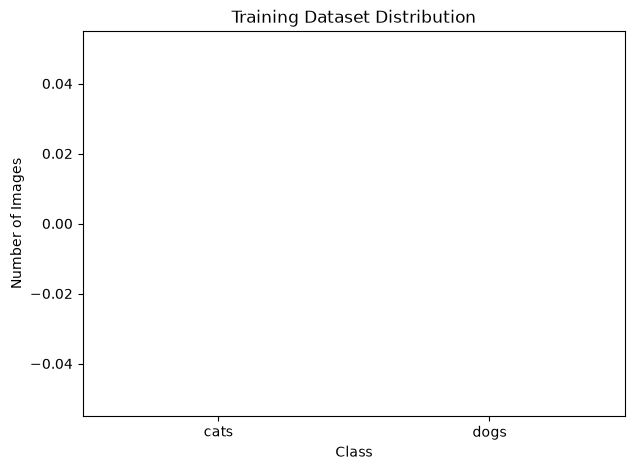

In [12]:
# Visualize the distribution

labels = list(train_counts.keys())
values = list(train_counts.values())

plt.figure(figsize=(7, 5))

sns.barplot(
    x=labels,
    y=values
)

plt.title("Training Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

In [13]:
# Create directories for training and validation

os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(VALIDATION_DIR, exist_ok=True)

for class_name in ["cats", "dogs"]:
    os.makedirs(
        os.path.join(TRAIN_DIR, class_name),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(VALIDATION_DIR, class_name),
        exist_ok=True
    )

print("Training and validation directories created.")

Training and validation directories created.


In [14]:
# Now let's create a function to split the data

def split_data(
    source_directory,
    train_directory,
    validation_directory,
    validation_split=0.2
):
    """
    Splits images from source_directory into
    training and validation directories.
    """

    classes = ["cats", "dogs"]

    for class_name in classes:

        source_class_dir = os.path.join(
            source_directory,
            class_name
        )

        train_class_dir = os.path.join(
            train_directory,
            class_name
        )

        validation_class_dir = os.path.join(
            validation_directory,
            class_name
        )

        # Get image files
        images = [
            file
            for file in os.listdir(source_class_dir)
            if file.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ]

        # Shuffle images
        random.shuffle(images)

        # Calculate split point
        split_point = int(
            len(images) * (1 - validation_split)
        )

        train_images = images[:split_point]
        validation_images = images[split_point:]

        print(
            f"\n{class_name}:"
            f"\nTraining: {len(train_images)}"
            f"\nValidation: {len(validation_images)}"
        )

        # Copy training images
        for image in train_images:

            source = os.path.join(
                source_class_dir,
                image
            )

            destination = os.path.join(
                train_class_dir,
                image
            )

            if not os.path.exists(destination):
                shutil.copy2(
                    source,
                    destination
                )

        # Copy validation images
        for image in validation_images:

            source = os.path.join(
                source_class_dir,
                image
            )

            destination = os.path.join(
                validation_class_dir,
                image
            )

            if not os.path.exists(destination):
                shutil.copy2(
                    source,
                    destination
                )

In [15]:
# Now let's call the function

split_data(
    ORIGINAL_TRAIN_DIR,
    TRAIN_DIR,
    VALIDATION_DIR,
    validation_split=0.2
)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\train\\cats'